In [ ]:
# ============================================
# 1. INSTALL APACHE SPARK + GRADIO
# ============================================
%pip -q install pyspark gradio

import os, sys, shutil, subprocess
print("Python:", sys.version)
print("Java executable:", shutil.which("java"))
print("Dependencies installed. The next cell configures Java automatically.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Java executable: /usr/bin/java
Dependencies installed. The next cell configures Java automatically.


In [ ]:
# ============================================
# 2. IMPORT LIBRARIES
# ============================================

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, to_timestamp, year, month, dayofmonth, hour, minute,
    dayofweek, avg, max, min, count, when, lag
)
from pyspark.sql.window import Window
from pyspark.sql.types import DoubleType

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================
# 3. CREATE SPARK SESSION (Colab-compatible Java detection)
# ============================================
import os, shutil, subprocess

java_executable = shutil.which("java")
if java_executable is None:
    print("Java not found; installing OpenJDK 17...")
    subprocess.run(["bash", "-lc", "apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless"], check=True)
    java_executable = shutil.which("java")

if java_executable:
    resolved_java = os.path.realpath(java_executable)
    os.environ["JAVA_HOME"] = os.path.dirname(os.path.dirname(resolved_java))
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ.get("PATH", "")
    print("JAVA_HOME:", os.environ["JAVA_HOME"])

from pyspark.sql import SparkSession

spark = (SparkSession.builder
    .appName("BigDataElectricityDemandForecasting")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)

JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64
Spark version: 4.0.4
Application: BigDataElectricityDemandForecasting


In [ ]:
# ============================================
# 4. DOWNLOAD DATASET
# ============================================
import requests, zipfile
from pathlib import Path

DATA_DIR = Path("/content/electricity_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
zip_path = DATA_DIR / "electricity.zip"
txt_path = DATA_DIR / "household_power_consumption.txt"
url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

if not txt_path.exists():
    print("Downloading UCI electricity dataset (this can take a minute)...")
    response = requests.get(url, timeout=(20, 240))
    response.raise_for_status()
    zip_path.write_bytes(response.content)
    if not zipfile.is_zipfile(zip_path):
        raise RuntimeError("The downloaded file is not a valid ZIP. Rerun this cell or check Colab internet access.")
    with zipfile.ZipFile(zip_path) as zf:
        matches = [n for n in zf.namelist() if n.endswith("household_power_consumption.txt")]
        if not matches:
            raise FileNotFoundError("The UCI ZIP did not contain household_power_consumption.txt")
        with zf.open(matches[0]) as fin, open(txt_path, "wb") as fout:
            import shutil as _shutil
            _shutil.copyfileobj(fin, fout)
    print("Dataset downloaded and extracted.")
else:
    print("Dataset already exists; using cached copy.")
print("Dataset path:", txt_path)
print("File size (MB):", round(txt_path.stat().st_size / (1024**2), 1))

Dataset downloaded and extracted.
Dataset path: /content/electricity_data/household_power_consumption.txt
File size (MB): 126.8


## 5. HDFS Storage — Optional for a Real Hadoop Cluster

For a real Hadoop installation, the raw dataset can be placed in HDFS:

```bash
hdfs dfs -mkdir -p /electricity/raw
hdfs dfs -put household_power_consumption.txt /electricity/raw/
```

Then Spark can read:

```python
spark.read.csv("hdfs:///electricity/raw/household_power_consumption.txt")
```

Because Google Colab does not provide a persistent Hadoop cluster, the runnable notebook uses `/content/electricity_data` as local storage. The Spark processing code remains transferable to HDFS.

In [ ]:
# ============================================
# 6. READ RAW DATA USING SPARK
# ============================================
raw_df = (spark.read.option("header", True).option("sep", ";")
          .option("mode", "PERMISSIVE").csv(str(txt_path)))
# Normalize any whitespace accidentally included in source headers.
raw_df = raw_df.toDF(*[name.strip() for name in raw_df.columns])
print("Raw schema:")
raw_df.printSchema()
raw_count = raw_df.count()
print("Number of raw records:", f"{raw_count:,}")
raw_df.show(5, truncate=False)

Raw schema:
root
 |-- Date: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Global_active_power: string (nullable = true)
 |-- Global_reactive_power: string (nullable = true)
 |-- Voltage: string (nullable = true)
 |-- Global_intensity: string (nullable = true)
 |-- Sub_metering_1: string (nullable = true)
 |-- Sub_metering_2: string (nullable = true)
 |-- Sub_metering_3: string (nullable = true)

Number of raw records: 2,075,259
+----------+--------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|Date      |Time    |Global_active_power|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+----------+--------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|16/12/2006|17:24:00|4.216              |0.418                |234.840|18.400          |0.000         |1.000         |17.000        |
|16/12/2006|

In [ ]:
# ============================================
# 7. CLEAN AND TRANSFORM DATA
# ============================================
from pyspark.sql.functions import concat, lit, col, when, to_timestamp, trim
from pyspark.sql.types import DoubleType

clean_df = raw_df
# Treat UCI's '?' missing-value marker as null, after trimming string fields.
for c, dtype in raw_df.dtypes:
    if dtype == "string":
        clean_df = clean_df.withColumn(c, when(trim(col(c)) == "?", None).otherwise(trim(col(c))))

# Keep the original time text; parse Date + Time directly to avoid date_format casting issues.
clean_df = clean_df.withColumn(
    "timestamp",
    to_timestamp(concat(col("Date"), lit(" "), col("Time")), "d/M/yyyy HH:mm:ss")
)

numeric_columns = ["Global_active_power", "Global_reactive_power", "Voltage",
                   "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
for c in numeric_columns:
    clean_df = clean_df.withColumn(c, col(c).cast(DoubleType()))

clean_df = (clean_df.filter(col("timestamp").isNotNull())
    .filter(col("Global_active_power").isNotNull())
    .withColumnRenamed("Global_active_power", "demand_kw")
    .select("timestamp", "demand_kw", "Global_reactive_power", "Voltage",
            "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3")
    .cache())

clean_count = clean_df.count()
print("Cleaned record count:", f"{clean_count:,}")
clean_df.printSchema()
clean_df.show(5, truncate=False)

Cleaned record count: 2,049,280
root
 |-- timestamp: timestamp (nullable = true)
 |-- demand_kw: double (nullable = true)
 |-- Global_reactive_power: double (nullable = true)
 |-- Voltage: double (nullable = true)
 |-- Global_intensity: double (nullable = true)
 |-- Sub_metering_1: double (nullable = true)
 |-- Sub_metering_2: double (nullable = true)
 |-- Sub_metering_3: double (nullable = true)

+-------------------+---------+---------------------+-------+----------------+--------------+--------------+--------------+
|timestamp          |demand_kw|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+-------------------+---------+---------------------+-------+----------------+--------------+--------------+--------------+
|2006-12-16 17:24:00|4.216    |0.418                |234.84 |18.4            |0.0           |1.0           |17.0          |
|2006-12-16 17:25:00|5.36     |0.436                |233.63 |23.0            |0.0           |1.0       

In [ ]:
# ============================================
# 8. MAPREDUCE USING SPARK RDD
# ============================================
from pyspark.sql.functions import to_date, hour

# Map each reading to ((date, hour), (demand_sum, record_count)).
keyed_readings = (clean_df
    .select(to_date("timestamp").alias("reading_date"), hour("timestamp").alias("reading_hour"), "demand_kw")
    .rdd
    .map(lambda row: ((row[0].isoformat(), int(row[1])), (float(row[2]), 1)))
)

# Reduce values sharing the same (date, hour) key.
reduced_readings = keyed_readings.reduceByKey(
    lambda left, right: (left[0] + right[0], left[1] + right[1])
)

mapreduce_rows = reduced_readings.map(
    lambda item: (item[0][0], item[0][1], item[1][0] / item[1][1], item[1][1])
)
mapreduce_df = spark.createDataFrame(
    mapreduce_rows,
    ["reading_date", "reading_hour", "average_demand_kw", "record_count"]
).orderBy("reading_date", "reading_hour").cache()

print("MapReduce output (first 20 date-hour groups):")
mapreduce_df.show(20, truncate=False)
print("Total date-hour groups:", f"{mapreduce_df.count():,}")


MapReduce output (first 20 date-hour groups):
+------------+------------+------------------+------------+
|reading_date|reading_hour|average_demand_kw |record_count|
+------------+------------+------------------+------------+
|2006-12-16  |17          |4.222888888888891 |36          |
|2006-12-16  |18          |3.6322            |60          |
|2006-12-16  |19          |3.4002333333333334|60          |
|2006-12-16  |20          |3.268566666666666 |60          |
|2006-12-16  |21          |3.0564666666666667|60          |
|2006-12-16  |22          |2.200133333333334 |60          |
|2006-12-16  |23          |2.0616000000000003|60          |
|2006-12-17  |0           |1.8824666666666674|60          |
|2006-12-17  |1           |3.3494000000000006|60          |
|2006-12-17  |2           |1.5872666666666668|60          |
|2006-12-17  |3           |1.6622000000000001|60          |
|2006-12-17  |4           |2.215766666666666 |60          |
|2006-12-17  |5           |1.996733333333334 |60      

In [ ]:
# ============================================
# 8. CHECK MISSING VALUES
# ============================================

clean_df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in clean_df.columns
]).show()

+---------+---------+---------------------+-------+----------------+--------------+--------------+--------------+
|timestamp|demand_kw|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+---------+---------+---------------------+-------+----------------+--------------+--------------+--------------+
|        0|        0|                    0|      0|               0|             0|             0|             0|
+---------+---------+---------------------+-------+----------------+--------------+--------------+--------------+



## 9. Feature Engineering

We create predictive time features:
- Year
- Month
- Day
- Hour
- Minute
- Day of week
- Weekend indicator
- Previous-minute electricity demand

The previous-demand feature is created with a Spark window function.

In [ ]:
# ============================================
# 9. FEATURE ENGINEERING
# ============================================
from pyspark.sql.functions import year, month, dayofmonth, hour, minute, dayofweek, when, lag, to_date
from pyspark.sql.window import Window

feature_df = (clean_df
    .withColumn("year", year("timestamp"))
    .withColumn("month", month("timestamp"))
    .withColumn("day", dayofmonth("timestamp"))
    .withColumn("hour", hour("timestamp"))
    .withColumn("minute", minute("timestamp"))
    .withColumn("day_of_week", dayofweek("timestamp"))
    .withColumn("is_weekend", when(dayofweek("timestamp").isin([1, 7]), 1).otherwise(0)))

# Partitioning by date lets Spark process each day in parallel. The first reading of each day
# has no previous reading and is removed below.
window_spec = Window.partitionBy(to_date("timestamp")).orderBy("timestamp")
feature_df = feature_df.withColumn("previous_demand", lag("demand_kw", 1).over(window_spec))
feature_df = feature_df.dropna(subset=["demand_kw", "previous_demand"]).cache()

print("Feature-engineered records:", f"{feature_df.count():,}")
feature_df.select("timestamp", "demand_kw", "hour", "day_of_week", "is_weekend", "previous_demand").show(10, truncate=False)

Feature-engineered records: 2,047,847
+-------------------+---------+----+-----------+----------+---------------+
|timestamp          |demand_kw|hour|day_of_week|is_weekend|previous_demand|
+-------------------+---------+----+-----------+----------+---------------+
|2006-12-16 17:25:00|5.36     |17  |7          |1         |4.216          |
|2006-12-16 17:26:00|5.374    |17  |7          |1         |5.36           |
|2006-12-16 17:27:00|5.388    |17  |7          |1         |5.374          |
|2006-12-16 17:28:00|3.666    |17  |7          |1         |5.388          |
|2006-12-16 17:29:00|3.52     |17  |7          |1         |3.666          |
|2006-12-16 17:30:00|3.702    |17  |7          |1         |3.52           |
|2006-12-16 17:31:00|3.7      |17  |7          |1         |3.702          |
|2006-12-16 17:32:00|3.668    |17  |7          |1         |3.7            |
|2006-12-16 17:33:00|3.662    |17  |7          |1         |3.668          |
|2006-12-16 17:34:00|4.448    |17  |7          |1 

# 10. Spark SQL — Electricity Demand Analysis

Spark SQL lets us perform SQL analytics over the large Spark DataFrame.

We calculate:
- Average demand by hour
- Peak demand by hour
- Monthly average demand
- Monthly peak demand
- Overall statistics

In [ ]:
# ============================================
# 10. REGISTER SPARK SQL TABLE
# ============================================

feature_df.createOrReplaceTempView("electricity")

hourly_analysis = spark.sql('''
    SELECT
        hour,
        ROUND(AVG(demand_kw), 3) AS average_demand_kw,
        ROUND(MAX(demand_kw), 3) AS peak_demand_kw,
        COUNT(*) AS records
    FROM electricity
    GROUP BY hour
    ORDER BY hour
''')

hourly_analysis.show(24)

+----+-----------------+--------------+-------+
|hour|average_demand_kw|peak_demand_kw|records|
+----+-----------------+--------------+-------+
|   0|            0.658|         7.698|  84065|
|   1|            0.539|         10.29|  85440|
|   2|            0.481|         6.248|  85439|
|   3|            0.445|         4.426|  85428|
|   4|            0.444|         4.796|  85317|
|   5|            0.454|         6.376|  85260|
|   6|            0.792|          8.31|  85259|
|   7|            1.502|         9.486|  85283|
|   8|            1.461|         8.126|  85295|
|   9|            1.332|         7.732|  85316|
|  10|            1.261|         9.078|  85248|
|  11|            1.246|         8.504|  85248|
|  12|            1.207|         9.224|  85317|
|  13|            1.145|          9.59|  85339|
|  14|            1.083|         8.418|  85404|
|  15|            0.991|         8.848|  85378|
|  16|            0.949|         8.446|  85335|
|  17|            1.055|        11.122| 

In [ ]:
# ============================================
# 11. MONTHLY ANALYSIS
# ============================================

monthly_analysis = spark.sql('''
    SELECT
        year,
        month,
        ROUND(AVG(demand_kw), 3) AS average_demand_kw,
        ROUND(MAX(demand_kw), 3) AS peak_demand_kw,
        COUNT(*) AS records
    FROM electricity
    GROUP BY year, month
    ORDER BY year, month
''')

monthly_analysis.show(50)

+----+-----+-----------------+--------------+-------+
|year|month|average_demand_kw|peak_demand_kw|records|
+----+-----+-----------------+--------------+-------+
|2006|   12|            1.902|         9.132|  21976|
|2007|    1|            1.546|         9.272|  44607|
|2007|    2|            1.401|          9.41|  40290|
|2007|    3|            1.319|         10.67|  44608|
|2007|    4|            0.891|          8.16|  39448|
|2007|    5|            0.986|         7.672|  44609|
|2007|    6|            0.827|         7.614|  43127|
|2007|    7|            0.667|          7.24|  44478|
|2007|    8|            0.764|         8.694|  44587|
|2007|    9|            0.969|          8.11|  43168|
|2007|   10|            1.104|         9.036|  44607|
|2007|   11|            1.295|         9.326|  43168|
|2007|   12|            1.627|         9.686|  44608|
|2008|    1|             1.46|        10.162|  44608|
|2008|    2|            1.182|         8.716|  41728|
|2008|    3|            1.24

In [ ]:
# ============================================
# 12. OVERALL STATISTICS
# ============================================

overall_stats = spark.sql('''
    SELECT
        COUNT(*) AS total_records,
        ROUND(AVG(demand_kw), 3) AS average_demand_kw,
        ROUND(MAX(demand_kw), 3) AS maximum_demand_kw,
        ROUND(MIN(demand_kw), 3) AS minimum_demand_kw
    FROM electricity
''')

overall_stats.show()

+-------------+-----------------+-----------------+-----------------+
|total_records|average_demand_kw|maximum_demand_kw|minimum_demand_kw|
+-------------+-----------------+-----------------+-----------------+
|      2047847|            1.092|           11.122|            0.076|
+-------------+-----------------+-----------------+-----------------+



## 13. Visualize Hourly Demand

Only the small aggregated Spark SQL result is converted to Pandas. The complete multi-million-row dataset stays in Spark.

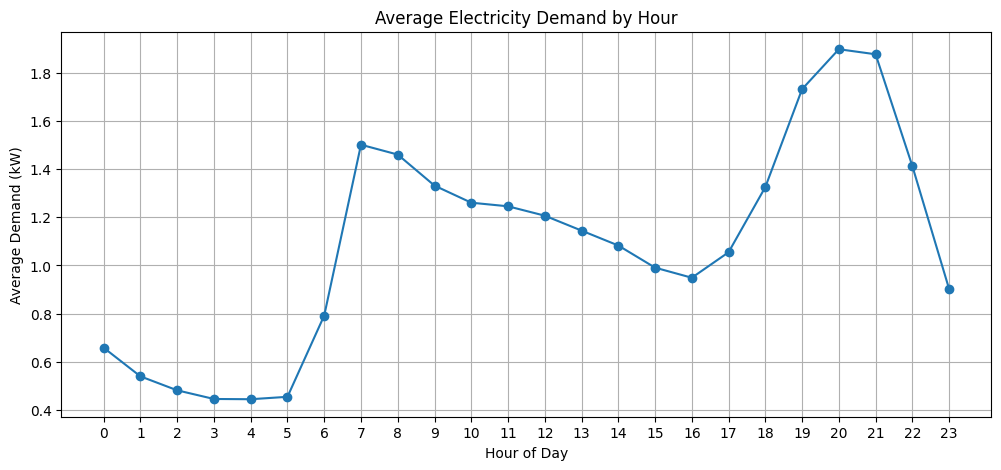

In [ ]:
# ============================================
# 13. HOURLY DEMAND VISUALIZATION
# ============================================

hourly_pd = hourly_analysis.toPandas()

plt.figure(figsize=(12, 5))
plt.plot(
    hourly_pd["hour"],
    hourly_pd["average_demand_kw"],
    marker="o"
)
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (kW)")
plt.title("Average Electricity Demand by Hour")
plt.xticks(range(24))
plt.grid(True)
plt.show()

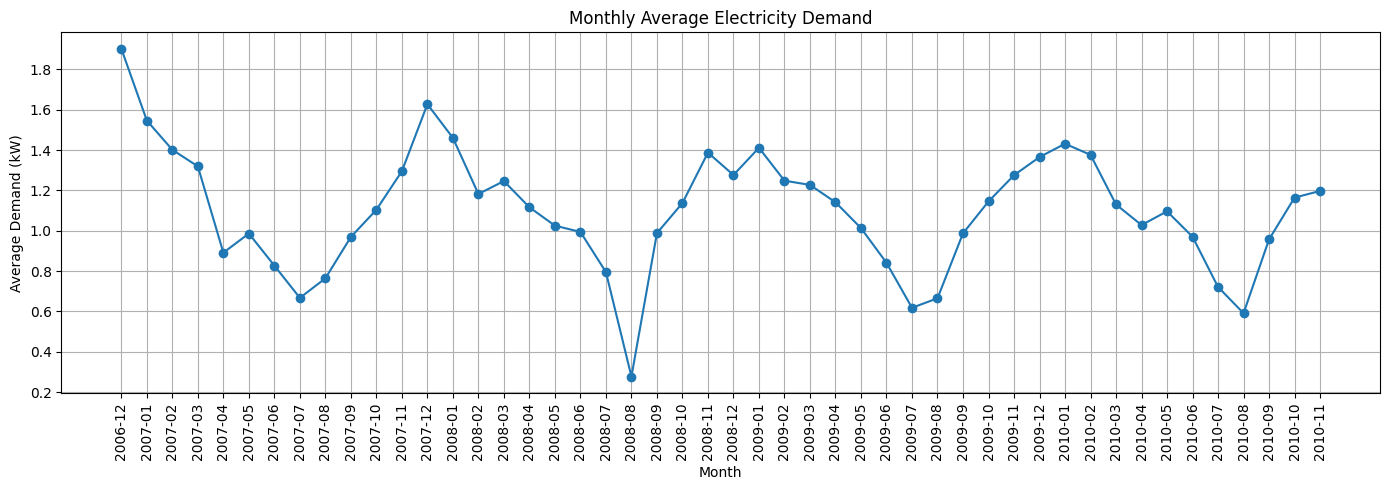

In [ ]:
# ============================================
# 14. MONTHLY DEMAND VISUALIZATION
# ============================================

monthly_pd = monthly_analysis.toPandas()

monthly_pd["period"] = (
    monthly_pd["year"].astype(str)
    + "-"
    + monthly_pd["month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_pd["period"],
    monthly_pd["average_demand_kw"],
    marker="o"
)
plt.xlabel("Month")
plt.ylabel("Average Demand (kW)")
plt.title("Monthly Average Electricity Demand")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

# 15. Electricity Demand Forecasting with Spark MLlib

We use **Random Forest Regression** from Spark MLlib.

### Features
- Year
- Month
- Day
- Hour
- Minute
- Day of week
- Weekend
- Previous demand
- Voltage
- Reactive power
- Global intensity
- Sub-metering values

### Target
`demand_kw`

The data is split **chronologically** so that the model trains on earlier observations and tests on later observations.

In [ ]:
train_df, test_df = ml_df.randomSplit([0.8, 0.2], seed=42)

In [ ]:
train_df, test_df = ml_df.randomSplit([0.8, 0.2], seed=42)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())
print("Columns:", train_df.columns)

Training rows: 108376
Testing rows: 26816
Columns: ['timestamp', 'demand_kw', 'year', 'month', 'day', 'hour', 'minute', 'day_of_week', 'is_weekend', 'previous_demand', 'Voltage', 'Global_reactive_power', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


In [ ]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features",
    handleInvalid="skip"
)

train_vector = assembler.transform(train_df).select(
    "timestamp", "features", "demand_kw"
)

test_vector = assembler.transform(test_df).select(
    "timestamp", "features", "demand_kw"
)

train_vector.show(5, truncate=False)

+-------------------+-------------------------------------------------------------------------+---------+
|timestamp          |features                                                                 |demand_kw|
+-------------------+-------------------------------------------------------------------------+---------+
|2006-12-16 17:30:00|[2006.0,12.0,16.0,17.0,30.0,7.0,1.0,3.52,235.09,0.52,15.8,0.0,1.0,17.0]  |3.702    |
|2006-12-16 17:45:00|[2006.0,12.0,16.0,17.0,45.0,7.0,1.0,5.894,230.98,0.0,33.2,0.0,0.0,17.0]  |7.706    |
|2006-12-16 18:15:00|[2006.0,12.0,16.0,18.0,15.0,7.0,1.0,2.388,234.25,0.1,21.4,0.0,20.0,17.0] |4.598    |
|2006-12-16 18:30:00|[2006.0,12.0,16.0,18.0,30.0,7.0,1.0,2.92,236.15,0.0,12.4,0.0,1.0,17.0]   |2.93     |
|2006-12-16 18:45:00|[2006.0,12.0,16.0,18.0,45.0,7.0,1.0,2.978,234.38,0.174,17.8,0.0,1.0,17.0]|4.2      |
+-------------------+-------------------------------------------------------------------------+---------+
only showing top 5 rows


In [ ]:
# ============================================
# 17. TRAIN RANDOM FOREST
# ============================================

rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="demand_kw",
    predictionCol="prediction",
    numTrees=30,
    maxDepth=8,
    seed=42
)

print("Training Spark Random Forest...")
rf_model = rf.fit(train_vector)

print("Model training completed.")

Training Spark Random Forest...
Model training completed.


In [ ]:
# ============================================
# 18. GENERATE PREDICTIONS
# ============================================

predictions = rf_model.transform(test_vector)

predictions.select(
    "timestamp",
    "demand_kw",
    "prediction"
).show(20)

+-------------------+---------+------------------+
|          timestamp|demand_kw|        prediction|
+-------------------+---------+------------------+
|2006-12-16 18:00:00|     2.79|2.5688301311766266|
|2006-12-16 19:00:00|     4.07| 4.536977521743369|
|2006-12-16 19:30:00|    3.408|3.2820960958501697|
|2006-12-16 20:45:00|    3.386| 3.287398868342386|
|2006-12-16 22:15:00|    2.778|2.7948342086620768|
|2006-12-16 23:15:00|    0.386|0.7382721491960073|
|2006-12-17 01:00:00|    1.008|1.4027111292659549|
|2006-12-17 02:30:00|    2.444|2.3575702789436117|
|2006-12-17 05:00:00|    2.294| 2.189047938785369|
|2006-12-17 05:15:00|     2.91|2.7141603445748297|
|2006-12-17 05:30:00|     1.65|1.6960697399451101|
|2006-12-17 06:00:00|    2.076| 2.131302740918493|
|2006-12-17 06:30:00|    3.328|3.1224051919252185|
|2006-12-17 07:30:00|    2.336| 2.381450946245924|
|2006-12-17 09:15:00|    2.372| 2.302952390956325|
|2006-12-17 11:00:00|     3.65|3.7978429658912063|
|2006-12-17 13:00:00|    1.754|

In [ ]:
# ============================================
# 19. MODEL EVALUATION
# ============================================

rmse_evaluator = RegressionEvaluator(
    labelCol="demand_kw",
    predictionCol="prediction",
    metricName="rmse"
)

mae_evaluator = RegressionEvaluator(
    labelCol="demand_kw",
    predictionCol="prediction",
    metricName="mae"
)

r2_evaluator = RegressionEvaluator(
    labelCol="demand_kw",
    predictionCol="prediction",
    metricName="r2"
)

rmse = rmse_evaluator.evaluate(predictions)
mae = mae_evaluator.evaluate(predictions)
r2 = r2_evaluator.evaluate(predictions)

print(f"RMSE: {rmse:.4f} kW")
print(f"MAE : {mae:.4f} kW")
print(f"R²  : {r2:.4f}")

RMSE: 0.1521 kW
MAE : 0.0564 kW
R²  : 0.9796


## 20. Actual vs Predicted Demand

We plot a sample of the test data so that the visualization remains lightweight.

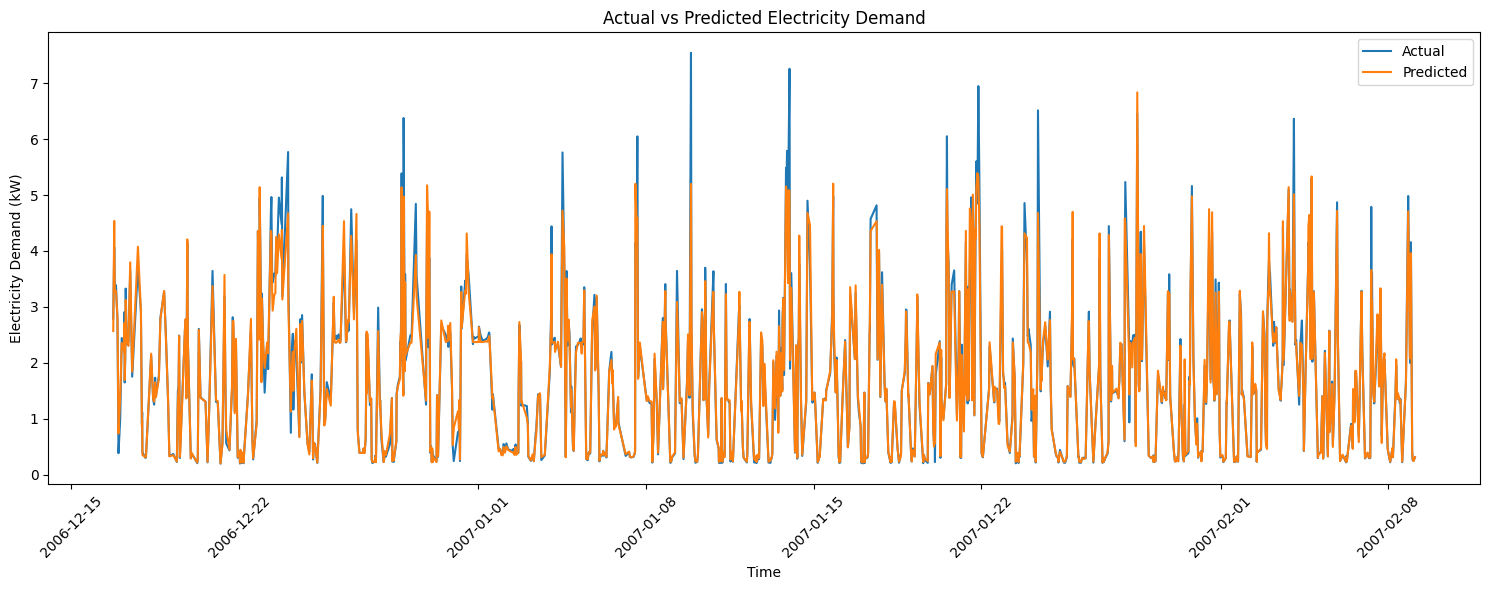

In [ ]:
# ============================================
# 20. ACTUAL VS PREDICTED
# ============================================

prediction_pd = (
    predictions
    .select("timestamp", "demand_kw", "prediction")
    .orderBy("timestamp")
    .limit(1000)
    .toPandas()
)

plt.figure(figsize=(15, 6))
plt.plot(
    prediction_pd["timestamp"],
    prediction_pd["demand_kw"],
    label="Actual"
)
plt.plot(
    prediction_pd["timestamp"],
    prediction_pd["prediction"],
    label="Predicted"
)
plt.xlabel("Time")
plt.ylabel("Electricity Demand (kW)")
plt.title("Actual vs Predicted Electricity Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 21. Random Forest Feature Importance

Spark MLlib provides feature importance scores, which help identify which variables contribute most to demand prediction.

,feature,importance
10,Global_intensity,0.515248
7,previous_demand,0.283132
13,Sub_metering_3,0.132701
12,Sub_metering_2,0.033998
11,Sub_metering_1,0.017576
9,Global_reactive_power,0.006270
8,Voltage,0.005167
3,hour,0.004415
1,month,0.000626
2,day,0.000246


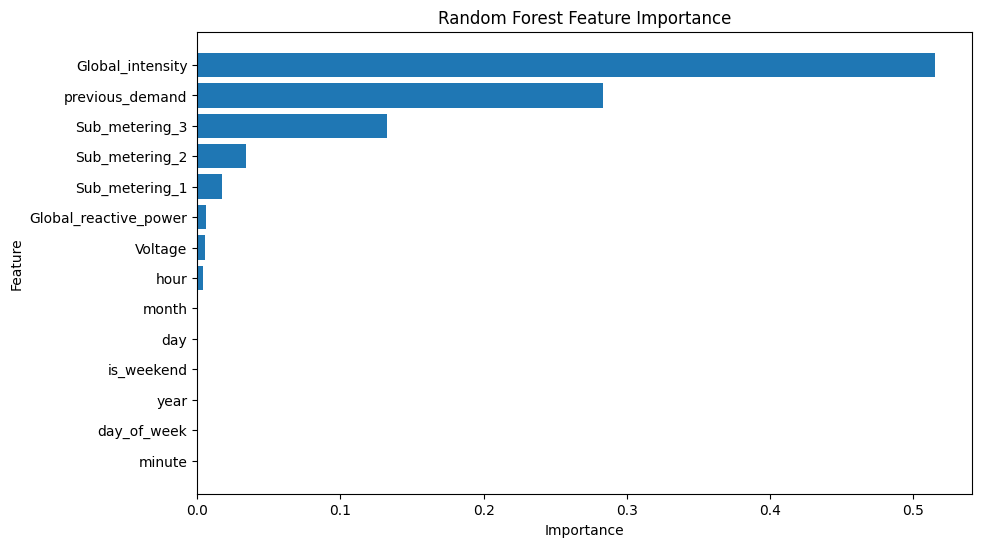

In [ ]:
# ============================================
# 21. FEATURE IMPORTANCE
# ============================================

importance = rf_model.featureImportances

importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": importance.toArray()
}).sort_values("importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

# 22. Save Processed Data as Parquet

Parquet is a columnar storage format commonly used with Spark and Hadoop because it is efficient for analytical queries.

In [ ]:
# ============================================
# 22. SAVE PROCESSED DATA
# ============================================

OUTPUT_DIR = "/content/electricity_output"

(
    feature_df
    .write
    .mode("overwrite")
    .parquet(OUTPUT_DIR)
)

print("Processed data saved to:", OUTPUT_DIR)

Processed data saved to: /content/electricity_output


# 23. Gradio Dashboard

A presentation layer for the existing Spark analysis. The dashboard includes:
- Dataset and model summary cards
- Hourly and monthly electricity demand trends
- Actual versus predicted demand visualization
- Model evaluation metrics (RMSE, MAE and R²)
- Random Forest feature-importance insights

Only the Gradio interface is customized; data ingestion, cleaning, feature engineering, Spark SQL, model training, evaluation and saved output logic remain unchanged.

In [ ]:
# ============================================
# 23. PREPARE DASHBOARD DATA
# ============================================
dashboard_predictions = (predictions.select("timestamp", "demand_kw", "prediction")
    .orderBy("timestamp").limit(2000).toPandas())
dashboard_hourly = hourly_analysis.toPandas()
dashboard_monthly = monthly_analysis.toPandas()
dashboard_mapreduce = mapreduce_df.limit(500).toPandas()
stats_row = overall_stats.first().asDict()

print("Dashboard data prepared.")

Dashboard data prepared.


In [ ]:
# ============================================
# 24. LAUNCH POLISHED GRADIO DASHBOARD
# (Only the dashboard interface is customized; the analysis pipeline is unchanged.)
# ============================================

import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd
import builtins

# Consistent visual style for dashboard charts
CHART_BG = "#101827"
ACCENT = "#38BDF8"

def _style_chart(ax, title, xlabel, ylabel):
    ax.set_facecolor(CHART_BG)
    ax.set_title(title, color="#F8FAFC", fontsize=13, fontweight="bold", pad=14)
    ax.set_xlabel(xlabel, color="#CBD5E1")
    ax.set_ylabel(ylabel, color="#CBD5E1")
    ax.tick_params(colors="#CBD5E1", labelsize=9)
    ax.grid(True, linestyle="--", alpha=0.18, color="#94A3B8")
    for spine in ax.spines.values():
        spine.set_color("#334155")

def get_hourly_chart():
    fig, ax = plt.subplots(figsize=(10, 3.8), facecolor=CHART_BG)
    ax.plot(dashboard_hourly["hour"], dashboard_hourly["average_demand_kw"],
            color=ACCENT, marker="o", markersize=4, linewidth=2.4)
    ax.fill_between(dashboard_hourly["hour"], dashboard_hourly["average_demand_kw"],
                    color=ACCENT, alpha=0.12)
    ax.set_xticks(range(0, 24, 2))
    _style_chart(ax, "Average Demand by Hour", "Hour of day", "Average demand (kW)")
    fig.tight_layout()
    return fig

def get_monthly_chart():
    fig, ax = plt.subplots(figsize=(10, 3.8), facecolor=CHART_BG)
    month_data = dashboard_monthly.copy()
    month_data["period"] = (month_data["year"].astype(str) + "-" +
                            month_data["month"].astype(str).str.zfill(2))
    ax.plot(month_data["period"], month_data["average_demand_kw"],
            color="#A78BFA", marker="o", markersize=3, linewidth=2)
    if len(month_data) > 18:
        # Use builtins.max to bypass PySpark's max function override
        tick_step = builtins.max(1, len(month_data) // 12)
        ax.set_xticks(range(0, len(month_data), tick_step))
        ax.set_xticklabels(month_data["period"].iloc[::tick_step], rotation=35, ha="right")
    else:
        ax.tick_params(axis="x", labelrotation=35)
    _style_chart(ax, "Monthly Average Electricity Demand", "Month", "Average demand (kW)")
    fig.tight_layout()
    return fig

def get_prediction_chart():
    sample = dashboard_predictions.tail(250).copy()
    fig, ax = plt.subplots(figsize=(10, 3.8), facecolor=CHART_BG)
    ax.plot(range(len(sample)), sample["demand_kw"], label="Actual",
            color="#38BDF8", linewidth=1.8)
    ax.plot(range(len(sample)), sample["prediction"], label="Predicted",
            color="#FBBF24", linewidth=1.8, alpha=0.95)
    _style_chart(ax, "Actual vs Predicted Demand (sample)", "Test sample index", "Demand (kW)")
    ax.legend(facecolor="#1E293B", edgecolor="#334155", labelcolor="#F8FAFC")
    fig.tight_layout()
    return fig

def get_feature_chart():
    fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=CHART_BG)
    top_features = importance_df.head(10).sort_values("importance", ascending=True)
    ax.barh(top_features["feature"], top_features["importance"], color="#34D399")
    _style_chart(ax, "Top 10 Feature Importances", "Importance score", "Feature")
    fig.tight_layout()
    return fig

def get_statistics_table():
    return pd.DataFrame([
        ["Raw dataset records", f"{2_075_259:,}"],
        ["Cleaned records", f"{clean_df.count():,}"],
        ["Records used for modeling", f"{ml_df.count():,}"],
        ["Training records (80% chronological split)", f"{train_df.count():,}"],
        ["Testing records", f"{test_df.count():,}"],
        ["Average demand", f"{stats_row['average_demand_kw']} kW"],
        ["Maximum demand", f"{stats_row['maximum_demand_kw']} kW"],
        ["Minimum demand", f"{stats_row['minimum_demand_kw']} kW"],
        ["RMSE", f"{rmse:.4f} kW"],
        ["MAE", f"{mae:.4f} kW"],
        ["R² score", f"{r2:.4f}"],
    ], columns=["Metric", "Value"])

custom_css = """
:root { --body-background-fill: #0b1120; --block-background-fill: #111b2e; --border-color-primary: #26354d; }
.gradio-container { max-width: 1250px !important; margin: auto !important; background: #0b1120 !important; }
#hero { padding: 30px 32px; border: 1px solid #26354d; border-radius: 22px;
        background: linear-gradient(120deg, #14233c 0%, #102b40 55%, #172554 100%); margin-bottom: 18px; }
#hero h1 { color: #f8fafc; font-size: 31px; margin: 0 0 8px 0; }
#hero p { color: #cbd5e1; font-size: 14px; margin: 4px 0; }
.pill { display: inline-block; padding: 5px 10px; margin: 10px 5px 0 0; border-radius: 99px;
        border: 1px solid #36516e; color: #bae6fd; font-size: 12px; }
.kpi { padding: 16px; border: 1px solid #26354d; border-radius: 15px; background: #111b2e; min-height: 86px; }
.kpi .label { color: #94a3b8; font-size: 12px; }
.kpi .value { color: #f8fafc; font-size: 24px; font-weight: 700; margin-top: 7px; }
.section-note { color: #94a3b8; font-size: 13px; }
footer { display: none !important; }
"""

with gr.Blocks(title="Electricity Demand | Big Data Analytics", theme=gr.themes.Soft(
    primary_hue="sky", secondary_hue="indigo", neutral_hue="slate"
), css=custom_css) as demo:
    gr.HTML("""
    <div id="hero">
      <p style="letter-spacing:2px;text-transform:uppercase;font-weight:700;color:#7dd3fc;">BIG DATA ANALYTICS • PROJECT DASHBOARD</p>
      <h1>⚡ Electricity Demand Analytics</h1>
      <p>Explore household electricity consumption, hourly and monthly trends, and Spark MLlib forecast performance.</p>
      <span class="pill">Apache Spark</span><span class="pill">Spark SQL</span>
      <span class="pill">Random Forest MLlib</span><span class="pill">UCI Household Dataset</span>
    </div>
    """)

    with gr.Row():
        gr.HTML(f'<div class="kpi"><div class="label">CLEANED RECORDS</div><div class="value">{clean_df.count():,}</div></div>')
        gr.HTML(f"<div class='kpi'><div class='label'>AVERAGE DEMAND</div><div class='value'>{stats_row['average_demand_kw']} kW</div></div>")
        gr.HTML(f'<div class="kpi"><div class="label">MODEL RMSE</div><div class="value">{rmse:.4f} kW</div></div>')
        gr.HTML(f'<div class="kpi"><div class="label">MODEL R²</div><div class="value">{r2:.4f}</div></div>')

    with gr.Tabs():
        with gr.Tab("📊 Overview"):
            gr.Markdown("### Dataset and model summary")
            gr.Dataframe(value=get_statistics_table(), label="Key metrics", interactive=False)
            gr.Markdown("<p class=\'section-note\'>The train/test split is chronological (80% training, 20% testing). Metrics are calculated on the held-out test data.</p>")
        with gr.Tab("🔀 MapReduce"):
            gr.Markdown("### Spark RDD MapReduce output")
            gr.Markdown("Each row represents one date-hour key. The mapper emits demand and count pairs; reduceByKey combines them to calculate the average.")
            gr.Dataframe(value=dashboard_mapreduce, label="Date-hour MapReduce results (first 500 groups)", interactive=False)

        with gr.Tab("🕒 Demand Trends"):
            gr.Markdown("### When does electricity demand change?")
            with gr.Row():
                gr.Plot(value=get_hourly_chart(), label="Hourly demand")
            with gr.Row():
                gr.Plot(value=get_monthly_chart(), label="Monthly demand")
            gr.Dataframe(value=dashboard_hourly, label="Hourly aggregate data", interactive=False)
        with gr.Tab("🎯 Forecast Results"):
            gr.Markdown("### Actual demand compared with Random Forest predictions")
            gr.Plot(value=get_prediction_chart(), label="Actual vs predicted")
            gr.Dataframe(value=dashboard_predictions.tail(100), label="Latest 100 rows in the dashboard sample", interactive=False)
            gr.Markdown(f"**Evaluation:** RMSE = `{rmse:.4f} kW` · MAE = `{mae:.4f} kW` · R² = `{r2:.4f}`")
        with gr.Tab("🧠 Feature Insights"):
            gr.Markdown("### Which inputs contributed most to the model?")
            gr.Plot(value=get_feature_chart(), label="Feature importance")
            gr.Dataframe(value=importance_df.head(10), label="Top 10 features", interactive=False)

    gr.Markdown("<p class=\'section-note\' style=\'text-align:center;padding:14px 0;\'>Built with PySpark • Spark SQL • Spark MLlib • Gradio | Academic project dashboard</p>")

try:
    demo.launch(share=True, debug=False)
except Exception as launch_error:
    print("Public Gradio link could not be created:", launch_error)
    print("Trying local launch instead. In Colab, rerun this cell if you need to retry the public link.")
    demo.launch(share=False, debug=False)

/tmp/ipykernel_666/1437862776.py:105: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Electricity Demand | Big Data Analytics", theme=gr.themes.Soft(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5f4b6b9f50de0df202.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
